Mild_Dementia: 10000 files
Moderate_Dementia: 8000 files
Non_Demented: 40000 files
Very_mild_Dementia: 20000 files
Epoch 1/50 | Loss=1563.6531 | Acc=0.6523
Epoch 2/50 | Loss=1268.5482 | Acc=0.7213
Epoch 3/50 | Loss=1157.5863 | Acc=0.7478
Epoch 4/50 | Loss=1086.1146 | Acc=0.7644
Epoch 5/50 | Loss=1034.1959 | Acc=0.7765
Epoch 6/50 | Loss=993.4786 | Acc=0.7863
Epoch 7/50 | Loss=958.2146 | Acc=0.7933
Epoch 8/50 | Loss=928.2943 | Acc=0.8001
Epoch 9/50 | Loss=892.5945 | Acc=0.8091
Epoch 10/50 | Loss=872.4855 | Acc=0.8130
Epoch 11/50 | Loss=849.1744 | Acc=0.8194
Epoch 12/50 | Loss=811.6010 | Acc=0.8298
Epoch 13/50 | Loss=797.8032 | Acc=0.8312
Epoch 14/50 | Loss=770.5892 | Acc=0.8396
Epoch 15/50 | Loss=749.7350 | Acc=0.8434
Epoch 16/50 | Loss=733.4336 | Acc=0.8473
Epoch 17/50 | Loss=713.8272 | Acc=0.8522
Epoch 18/50 | Loss=686.8586 | Acc=0.8586
Epoch 19/50 | Loss=668.9366 | Acc=0.8629
Epoch 20/50 | Loss=650.0469 | Acc=0.8656
Epoch 21/50 | Loss=632.7159 | Acc=0.8716
Epoch 22/50 | Loss=617.9625 

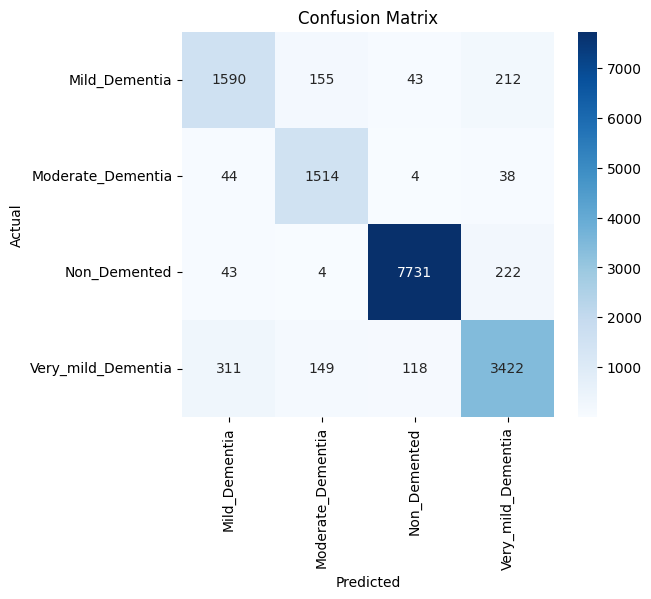

In [3]:
import os
import glob
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

dataset_dir = "C:/Users/sanja/Desktop/MRI_Project/AD_DATASET/Processed_Final"

# EXACT FOLDER NAMES FROM YOUR SCREENSHOT
classes = [
    "Mild_Dementia",
    "Moderate_Dementia",
    "Non_Demented",
    "Very_mild_Dementia"
]

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 50
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------
# LOAD IMAGES
# -------------------------------

image_paths = []
labels = []

for class_idx, class_name in enumerate(classes):
    class_path = os.path.join(dataset_dir, class_name)
    files = glob.glob(class_path + "/*.*")   # accept .jpg/.png/.jpeg etc.
    print(f"{class_name}: {len(files)} files")

    for img in files:
        image_paths.append(img)
        labels.append(class_idx)

if len(image_paths) == 0:
    raise ValueError("No images found. Check folder structure again.")

# -------------------------------
# TRAIN / TEST SPLIT
# -------------------------------

train_paths, test_paths, train_labels, test_labels = train_test_split(
    image_paths, labels, test_size=0.2, random_state=42, stratify=labels
)

# -------------------------------
# DATASET CLASS
# -------------------------------

class MRIDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        label = self.labels[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

# -------------------------------
# TRANSFORMS
# -------------------------------

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

train_dataset = MRIDataset(train_paths, train_labels, transform)
test_dataset = MRIDataset(test_paths, test_labels, transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# -------------------------------
# RESNET50 MODEL
# -------------------------------

model = models.resnet50(weights="IMAGENET1K_V2")

for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Sequential(
    nn.Linear(model.fc.in_features, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 4)
)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=1e-4)

# -------------------------------
# TRAIN LOOP
# -------------------------------

for epoch in range(EPOCHS):
    model.train()
    total_loss, total_correct, total_samples = 0, 0, 0

    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)

        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, lbls)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, pred = out.max(1)
        total_correct += pred.eq(lbls).sum().item()
        total_samples += lbls.size(0)

    acc = total_correct / total_samples
    print(f"Epoch {epoch+1}/{EPOCHS} | Loss={total_loss:.4f} | Acc={acc:.4f}")

# -------------------------------
# EVALUATION
# -------------------------------

model.eval()
all_preds, all_true = [], []
correct, total = 0, 0

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
        out = model(imgs)
        _, pred = out.max(1)

        all_preds.extend(pred.cpu().numpy())
        all_true.extend(lbls.cpu().numpy())

        correct += pred.eq(lbls).sum().item()
        total += lbls.size(0)

print(f"\nTest Accuracy: {correct/total*100:.2f}%")

print("\nClassification Report:")
print(classification_report(all_true, all_preds, target_names=classes))

cm = confusion_matrix(all_true, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


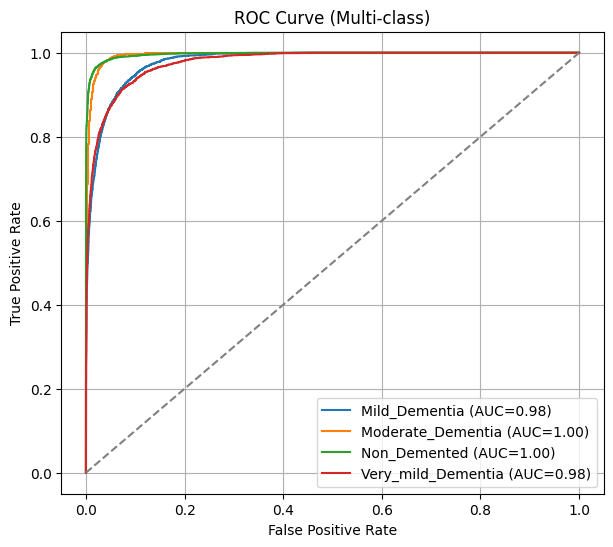

In [4]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt

model.eval()

all_probs = []
all_true = []

with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(DEVICE)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1).cpu().numpy()

        all_probs.append(probs)
        all_true.append(lbls.numpy())

all_probs = np.vstack(all_probs)
all_true = np.hstack(all_true)

# One-hot encode labels for ROC
y_true_bin = label_binarize(all_true, classes=[0,1,2,3])

plt.figure(figsize=(7,6))

for i, class_name in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_name} (AUC={roc_auc:.2f})")

plt.plot([0,1], [0,1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Multi-class)")
plt.legend()
plt.grid()
plt.show()


In [5]:
plt.figure(figsize=(7,5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


NameError: name 'train_losses' is not defined

<Figure size 700x500 with 0 Axes>

In [ ]:
plt.figure(figsize=(7,5))
plt.plot(lrs)
plt.title("Learning Rate Curve")
plt.xlabel("Iteration")
plt.ylabel("Learning Rate")
plt.grid()
plt.show()
